# 07 · Parallax, orbital motion and binary sources

Higher-order effects change the light curve of long events: the orbit of the Earth (annual **microlens
parallax** π_E), the orbit of the lens (**lens orbital motion**, ds/dt and dα/dt), and a **binary source** can
mimic a planet. This notebook simulates an event with parallax, recovers it, shows the u0 ↔ −u0 degeneracy, and
fits a binary-source model.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import lenscape
from lenscape import config, figures
from scipy.optimize import minimize
from lenscape import lightcurve as L, single

## A simulated event with parallax

`lightcurve.Trajectory` precomputes the Earth's motion for the data times and the event coordinates;
`HighOrder.mag(p)` evaluates p = (t0, u0, tE, log s, log q, α, log ρ, π_E,N, π_E,E[, ds/dt, dα/dt]).

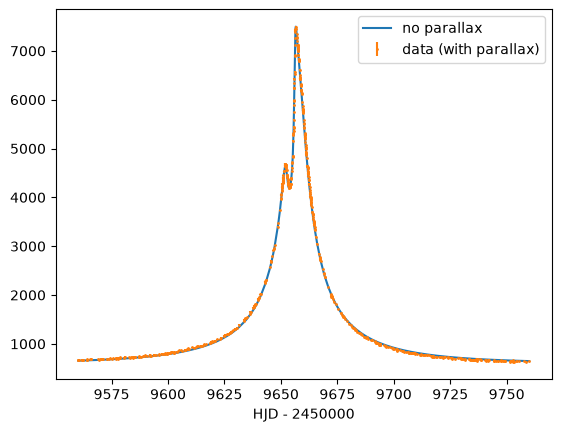

In [2]:
RA, DEC = "17:55:46.13", "-32:20:29.18"            # MOA-2022-BLG-091
rng = np.random.default_rng(3)
t = np.sort(np.r_[rng.uniform(9560, 9760, 400), rng.uniform(9650, 9665, 200)])   # HJD - 2450000
truth = np.array([9657.0, 0.08, 60.0, np.log10(1.15), np.log10(4e-3), 4.2, -3.0, 0.25, -0.12])
traj = L.Trajectory(t, 2450000.0, RA, DEC, t0par=9657.0)
ho = L.HighOrder(traj, tol=1e-3, hexeps=1e-4, ctol=0.01)
A = ho.mag(truth)
err = np.full(len(t), 8.0)
data = lenscape.Data(t, 500 * A + 100 + rng.normal(0, 8.0, len(t)), err, np.zeros(len(t), int), ["sim"])
plt.plot(t, 500 * ho.mag(np.r_[truth[:7], 0, 0]) + 100, label="no parallax")
plt.errorbar(t, data.f, err, fmt=".", ms=2, label="data (with parallax)"); plt.legend(); plt.xlabel("HJD - 2450000");

## Static vs. parallax fit

In [3]:
def fit(p0, n=3):
    f = lambda p: L.chi2(ho, p, data)
    p = np.asarray(p0, float)
    for _ in range(n):
        r = minimize(f, p, method="Nelder-Mead", options=dict(maxfev=8000, xatol=1e-8, fatol=1e-3, adaptive=True))
        p = r.x
    return r.fun, p

c_static, p_static = fit(np.r_[truth[:7], 0.0, 0.0][:7])
c_par, p_par = fit(truth + np.r_[np.zeros(7), 0.05, 0.05])
print(f"static chi2 {c_static:.1f}, parallax chi2 {c_par:.1f}  (N = {len(data)}): delta chi2 = {c_static - c_par:.0f}")
print(f"pi_E = ({p_par[7]:.3f}, {p_par[8]:.3f}), true ({truth[7]}, {truth[8]})")

static chi2 3352.3, parallax chi2 585.7  (N = 600): delta chi2 = 2767
pi_E = (0.121, -0.120), true (0.25, -0.12)


The parallax is detected clearly, but only one of its components is measured well: the acceleration of the
Earth during a few weeks constrains the component roughly along the Earth's acceleration (here mostly east-west,
π_E,E), while the perpendicular component (π_E,N) stays poorly constrained. This "one-dimensional parallax" is
typical of ground-based events.

## The ecliptic degeneracy

Reflecting the trajectory, (u0, α, π_E,N) → (−u0, −α, −π_E,N), gives almost the same light curve for events near
the ecliptic. Both solutions must be fitted and reported.

In [4]:
mirror = p_par.copy(); mirror[1] *= -1; mirror[5] = -mirror[5]; mirror[7] *= -1
c_mirror, p_mirror = fit(mirror)
print(f"u0 > 0: chi2 {c_par:.1f}   u0 < 0: chi2 {c_mirror:.1f}   (pi_E,N = {p_par[7]:.3f} vs {p_mirror[7]:.3f})")

u0 > 0: chi2 585.7   u0 < 0: chi2 586.3   (pi_E,N = 0.121 vs 0.051)


## Lens orbital motion

ds/dt (Einstein radii per year) and dα/dt (radians per year) change the caustic during the event.

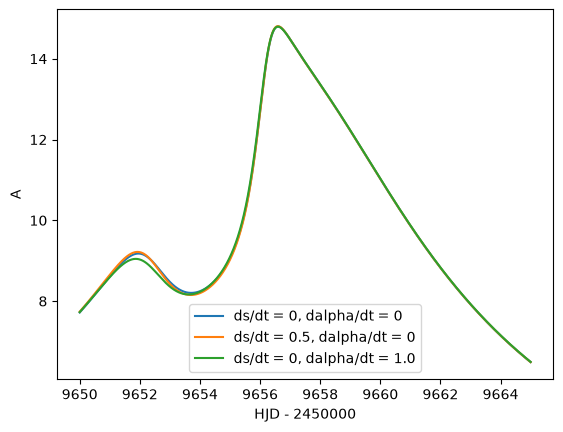

In [5]:
tz = np.linspace(9650, 9665, 2000)
hz = L.HighOrder(L.Trajectory(tz, 2450000.0, RA, DEC, 9657.0), 1e-3, 1e-4, 0.01)
for dsdt, dadt in ((0, 0), (0.5, 0), (0, 1.0)):
    plt.plot(tz, hz.mag(np.r_[truth, dsdt, dadt]), label=f"ds/dt = {dsdt}, dalpha/dt = {dadt}")
plt.legend(); plt.xlabel("HJD - 2450000"); plt.ylabel("A");

## Binary source

A second source star can produce a short bump like a planet. `single.chi2_1l2s` fits the binary-source model,
p = (t0₁, u0₁, t0₂, u0₂, tE, log ρ₁, log ρ₂, log q_F) with the flux ratio q_F.

1L2S chi2 514.5 for 500 points; flux ratio 0.049 (true 0.05)


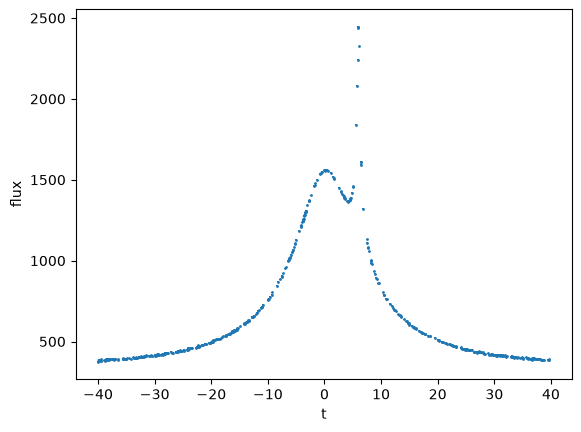

In [6]:
tb = np.sort(rng.uniform(-40, 40, 500))
true2 = (0.0, 0.2, 6.0, 0.01, 25.0, 10 ** -2.5, 10 ** -2.5, 0.05)
Ab = single.lc_1l2s(*true2, tb, 0.0)
bs = lenscape.Data(tb, 300 * Ab + 50 + rng.normal(0, 3, 500), np.full(500, 3.0), np.zeros(500, int), ["sim"])
start2 = np.array([0.1, 0.18, 6.1, 0.012, 24.0, -2.5, -2.5, np.log10(0.05)])
r = minimize(lambda p: single.chi2_1l2s(p, bs), start2, method="Nelder-Mead",
             options=dict(maxfev=8000, xatol=1e-8, fatol=1e-3, adaptive=True))
print(f"1L2S chi2 {r.fun:.1f} for {len(bs)} points; flux ratio {10 ** r.x[7]:.3f} (true 0.05)")
plt.errorbar(tb, bs.f, 3, fmt=".", ms=2); plt.xlabel("t"); plt.ylabel("flux");